# Compare DMS data to natural sequences

In [1]:
# Imports
import os
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
from Bio import SeqIO, AlignIO 


# Plotting colors
# re-arranged for plot
tol_muted_adjusted = [
    "#AA4499",
    "#88CCEE",
    "#EE7733",
    "#44AA99",
    "#1f78b4",
    "#CC6677",
    "#117733",
    "#999933",
    "#DDCC77",
    "#CC3311",
    "#882255",
    "#000000",
    "#DDDDDD",
]

# Seaborn style settings
sns.set(rc={
    "figure.dpi":300, 
    "savefig.dpi":300,
    "svg.fonttype":"none",
})
sns.set_style("ticks")
sns.set_palette(tol_muted_adjusted)

In [2]:
# this cell is tagged as `parameters` for papermill parameterization
dms_scores = None


In [3]:
# Uncomment for running interactive
dms_scores = "../results/summaries/cell_entry_and_pH_stability.csv"
alignment = "../non-pipeline_analyses/protein_ungapped_no_outgroup.fasta"
metadata = "../non-pipeline_analyses/metadata.tsv"
out_dir = "../results/comparison_to_natural_seqs/"

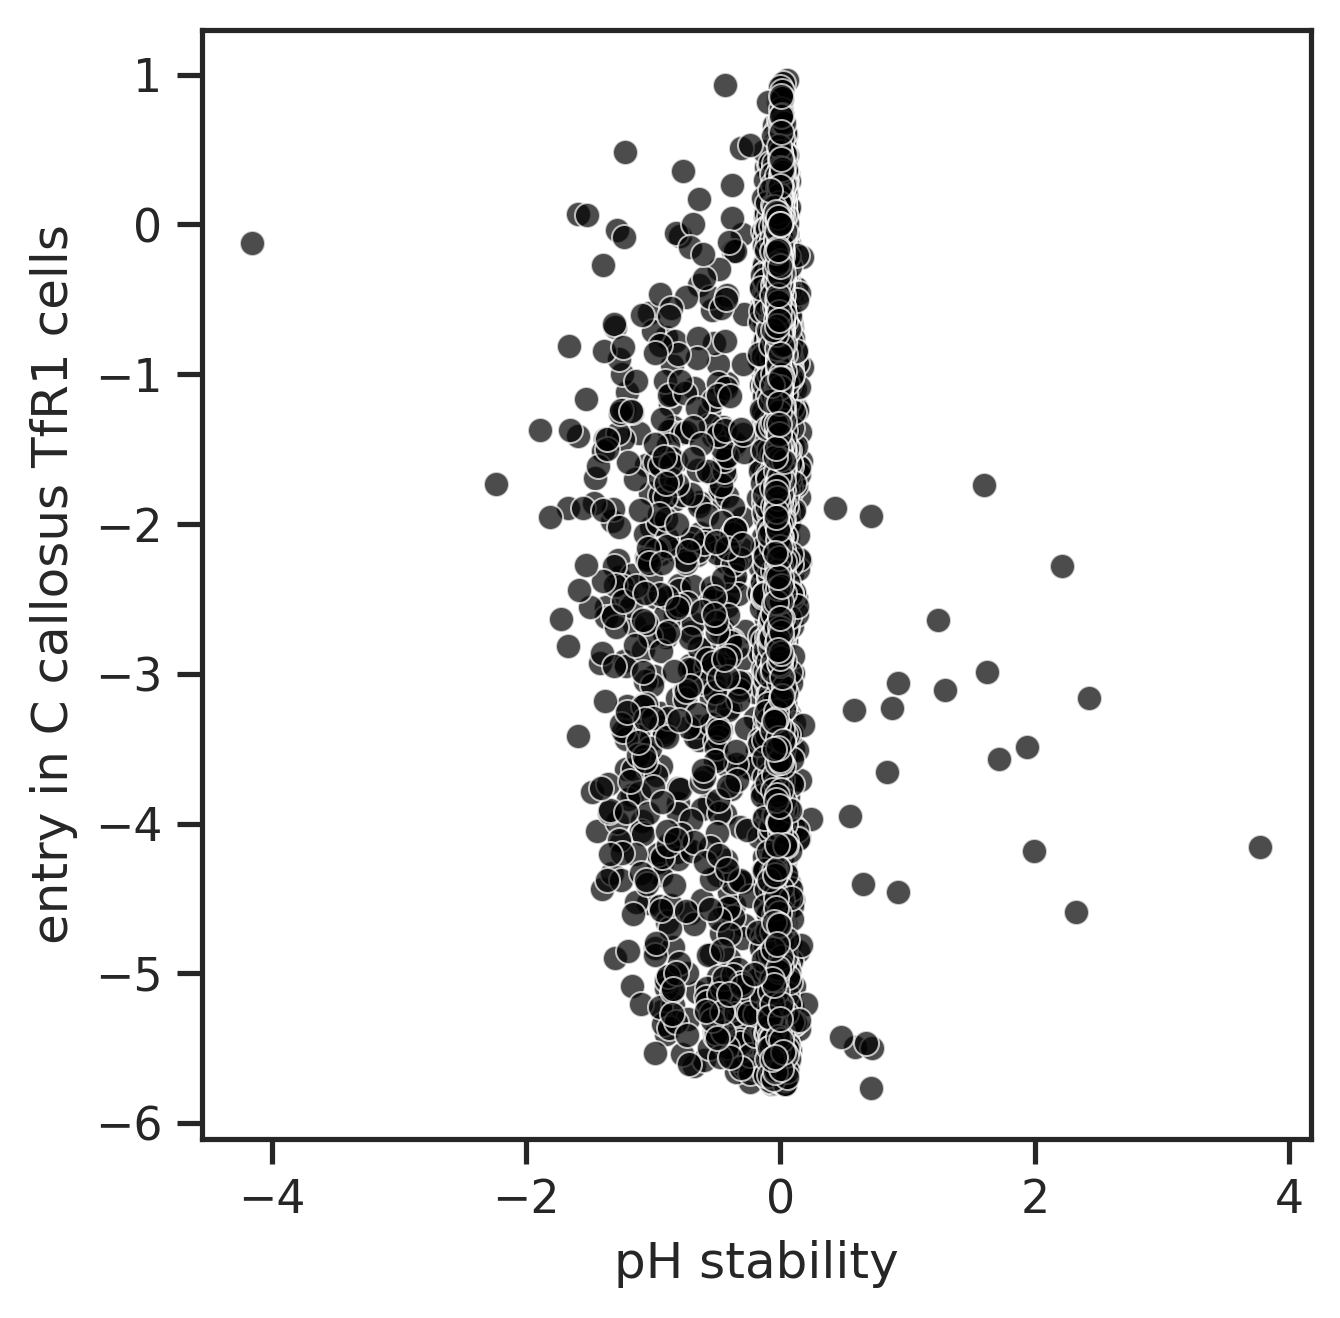

In [8]:
test = pd.read_csv(dms_scores)

corr_chart = sns.scatterplot(
    test, 
    y="entry in C callosus TfR1 cells", 
    x="pH stability",
    color="black",
    alpha=0.7,
)

corr_chart.set_box_aspect(1) 

# plt.savefig("pH_vs_cell_entry.svg")

In [4]:
def get_natural_sequence_counts(site: int, amino_acid: str, sequences: pd.Series) -> pd.Series:
    """
    Vectorized count of amino acid occurrences at a site across sequences.
    Uses str accessor for fast element-wise comparison instead of Python loop.
    """
    return (sequences.str[site - 1] == amino_acid).sum()

# Load alignment
natural_seqs_df = pd.DataFrame(
    [{"strain": str(r.id), "sequence": str(r.seq)} for r in AlignIO.read(alignment, "fasta")]
)

# Load metadata and merge with sequences
metadata_df = pd.read_csv(metadata, sep="\t")         
natural_seqs_df = natural_seqs_df.merge(
    metadata_df, how="left", on="strain", validate="one_to_one"
)

# Extract vaccine related sequences
vaccine_related = natural_seqs_df.query("candid_related == 'yes'")
natural_seqs_df = natural_seqs_df.query("candid_related == 'no'")


# Extract DMS parental sequence
ROMERO_STRAIN = "Romero_P3235_MW227339-1_2017-03-16"
SEQ_LEN = 485
romero_sequence = natural_seqs_df.loc[
    natural_seqs_df["strain"] == ROMERO_STRAIN, "sequence"
].iat[0]

# Create a wildtype df to fill in missing Josiah/wildtype measurements as 0
romero_df = pd.DataFrame({
    "site":             range(1, SEQ_LEN + 1),
    "wildtype":         list(romero_sequence),
    "mutant":           list(romero_sequence),
    "entry in C musculinus TfR1 cells":     0,
    "entry in C callosus TfR1 cells":       0,
    "pH stability":                         0,
    "Romero reference":                  True,
})

# Load DMS scores
scores = pd.read_csv(dms_scores)

# Combine DMS data and reference data
AA_level_df = (
    pd.concat([scores, romero_df], ignore_index=True)
    .sort_values("site")
    .fillna(False)
    .reset_index(drop=True)
)

# Drop gaps and wildtype counts
AA_level_df = (
    AA_level_df
    .query("wildtype != mutant and mutant != '-'")
    .reset_index(drop=True)
)

# Group sites so each unique site queries the sequence column only once
sequences = natural_seqs_df["sequence"]
vaccine_seqs = vaccine_related["sequence"]

site_to_counts = {
    site: sequences.str[site - 1].value_counts()
    for site in AA_level_df["site"].unique()         
}

site_to_counts_vaccine = {
    site: vaccine_seqs.str[site - 1].value_counts()
    for site in AA_level_df["site"].unique()         
}

AA_level_df["natural_counts"] = AA_level_df.apply(
    lambda x: site_to_counts[x["site"]].get(x["mutant"], 0), axis=1
)

AA_level_df["vaccine_related_counts"] = AA_level_df.apply(
    lambda x: site_to_counts_vaccine[x["site"]].get(x["mutant"], 0), axis=1
)

# Drop unseen mutants now, before the bin expansion, to keep frame small.
AA_level_df = (
    AA_level_df
    .query("natural_counts > 0 or vaccine_related_counts > 0")
    .reset_index(drop=True)
)

AA_level_df.tail(50)

/tmp/ipykernel_10663/1105462763.py:49: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  .fillna(False)


,site,wildtype,mutant,entry in C callosus TfR1 cells,entry in C musculinus TfR1 cells,pH stability,sequential_site,region,Romero reference,natural_counts,vaccine_related_counts
18,93,T,N,-0.5253,-0.5102,-0.01771,93.0,GP1,False,4,0
19,105,N,D,-0.1292,-0.1021,-0.003017,105.0,GP1,False,2,0
20,107,S,T,0.1096,0.0172,0.005173,107.0,GP1,False,12,0
21,109,M,Q,-0.3643,-0.7679,0.01525,109.0,GP1,False,11,17
22,109,M,K,0.4868,0.1155,0.001602,109.0,GP1,False,2,3
23,110,I,F,-0.3819,-0.5453,0.01082,110.0,GP1,False,1,0
24,111,S,T,0.3135,0.259,0.01944,111.0,GP1,False,9,0
25,111,S,N,0.1037,0.1161,-0.008116,111.0,GP1,False,3,0
26,116,E,T,-2.552,-3.609,False,116.0,GP1,False,1,0
27,116,E,A,-1.389,-2.108,-0.002406,116.0,GP1,False,63,20


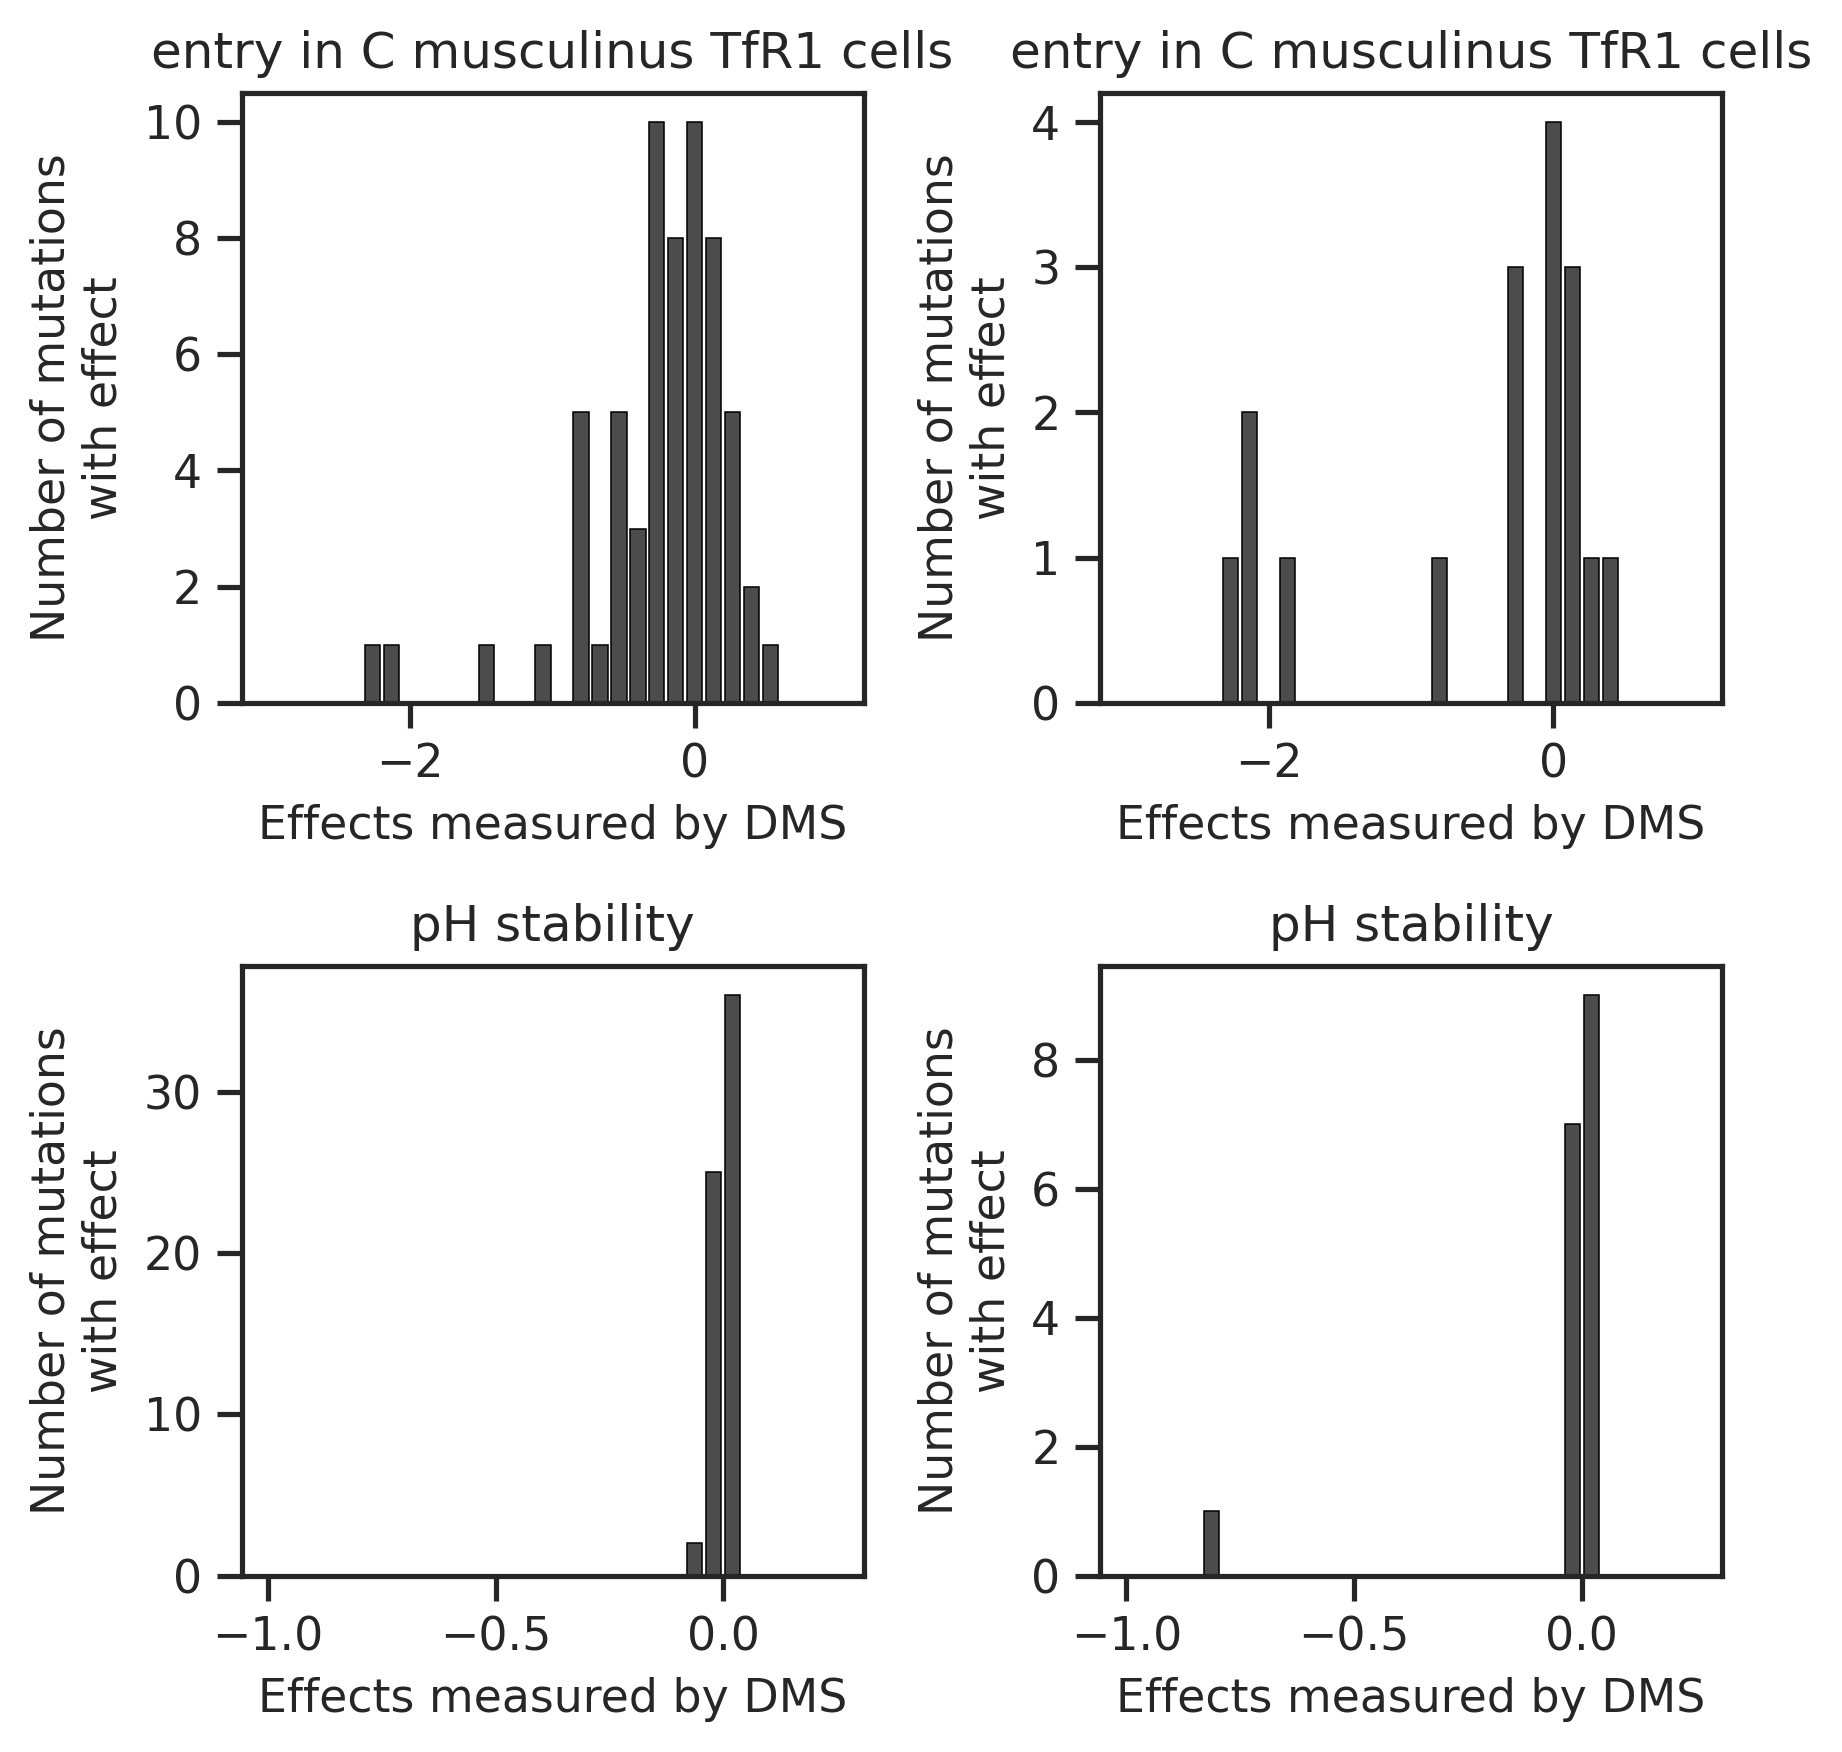

In [5]:
# Define the metrics to facet by
metrics = [
    # "entry in C callosus TfR1 cells",
    "entry in C musculinus TfR1 cells",
    "pH stability",
]
seq_status = [
    "natural_counts",
    "vaccine_related_counts",
]
 
# Create figure with subplots (1 row, 3 columns)
fig, axes = plt.subplots(2, 2, figsize=(6, 6))
 
# Plot histplot for each metric
for index_1, seq in enumerate(seq_status):
    for index_2, metric in enumerate(metrics):
        # Remove NaN/inf values for cleaner plotting
        data_to_plot = AA_level_df.query(f"{seq} > 0")[metric] #.replace([np.inf, -np.inf], np.nan).dropna()

        binrange = None
        if index_2 == 1:
            binrange = (-1,0.25)
        else:
            binrange = (-3,1)
        
        sns.histplot(
            data=data_to_plot,
            ax=axes[index_2][index_1],
            bins=30,
            binrange=binrange,
            stat="count",
            color="black",
            edgecolor="black",
            alpha=0.7,
            shrink=0.8,
        )
        
        axes[index_2][index_1].set_title(f"{metric}", fontsize=12)
        axes[index_2][index_1].set_xlabel("Effects measured by DMS", fontsize=11)
        axes[index_2][index_1].set_ylabel("Number of mutations\nwith effect", fontsize=11)
        axes[index_2][index_1].grid(False)

fig.tight_layout()

# Make output dir if doesn't exist
if not os.path.exists(out_dir):
    os.mkdir(out_dir)

# Save figure
plt.savefig(out_dir + "func_pH_effects_natural_seqs.svg")
plt.show()